In [1]:
%%writefile utils.py
import torch
import torch.nn as nn
from torch.amp import autocast, GradScaler
from tqdm.notebook import tqdm
import numpy as np


# =========================================================
# Conv Block
# =========================================================
class MyConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch, dropout_p):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride=1, padding=1),
            nn.BatchNorm2d(out_ch, momentum=0.1),
            nn.ReLU(inplace=True),
            nn.Dropout2d(dropout_p),
            nn.MaxPool2d(2, stride=2),
        )
    def forward(self, x):
        return self.model(x)


# =========================================================
# Mixup + CutMix
# =========================================================
def mixup_cutmix(x, y, n_classes, alpha=0.2, beta=1.0):
    """
    Áp dụng ngẫu nhiên Mixup hoặc CutMix.
    Trả về: (x_mixed, y_soft_onehot) hoặc (x, y) nếu không mix.
    """
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)

    # One-hot labels (tạo 1 lần, dùng chung)
    y_onehot = torch.zeros(batch_size, n_classes, device=x.device)
    y_onehot.scatter_(1, y.unsqueeze(1), 1)

    # Chọn Mixup hay CutMix
    if np.random.rand() < 0.5:
        # ---- MIXUP ----
        lam = np.random.beta(alpha, alpha)
        x_mixed = lam * x + (1 - lam) * x[index]
        y_mixed = lam * y_onehot + (1 - lam) * y_onehot[index]

    else:
        # ---- CUTMIX ----
        lam = np.random.beta(beta, beta)
        H, W = x.size(2), x.size(3)
        cut_rat = np.sqrt(1 - lam)
        cut_h, cut_w = int(H * cut_rat), int(W * cut_rat)

        cy, cx = np.random.randint(0, H), np.random.randint(0, W)
        y1 = max(0, cy - cut_h // 2)
        y2 = min(H, cy + cut_h // 2)
        x1 = max(0, cx - cut_w // 2)
        x2 = min(W, cx + cut_w // 2)

        x_mixed = x.clone()
        x_mixed[:, :, y1:y2, x1:x2] = x[index, :, y1:y2, x1:x2]

        # λ thực = diện tích vùng dán (đảo ngược từ cut_rat)
        lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
        y_mixed = lam * y_onehot + (1 - lam) * y_onehot[index]

    return x_mixed, y_mixed


# =========================================================
# Train 1 epoch
# =========================================================
def train_one_epoch(model, loader, N, random_trans, optimizer,
                    loss_function, scaler, device,
                    n_classes=266, use_mixup=True, mixup_prob=0.5):
    model.train()
    total_loss = 0.0
    total_correct = 0

    pbar = tqdm(loader, desc="Train", leave=False)
    for x, y in pbar:
        x = random_trans(x).to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad()

        with autocast("cuda"):
            if use_mixup and np.random.rand() < mixup_prob:
                # ⭐ Mixup hoặc CutMix
                x_mixed, y_soft = mixup_cutmix(x, y, n_classes)

                output = model(x_mixed)

                # ⭐ Soft label loss (CrossEntropy với one-hot)
                loss = -(y_soft * torch.log_softmax(output, dim=1)).sum(dim=1).mean()

                # ⭐ Accuracy nhanh — vectorized (KHÔNG dùng vòng lặp)
                pred = output.argmax(dim=1)                          # (B,)
                correct_mask = y_soft.gather(1, pred.unsqueeze(1)).squeeze(1) > 0.5
                total_correct += correct_mask.sum().item()

            else:
                # ⭐ Không mixup — chuẩn
                output = model(x)
                loss = loss_function(output, y)
                total_correct += (output.argmax(dim=1) == y).sum().item()

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * x.size(0)

        pbar.set_postfix({
            "loss": f"{loss.item():.3f}",
            "acc" : f"{total_correct / N * 100:.1f}%"
        })

    return total_loss / N, total_correct / N


# =========================================================
# Validate
# =========================================================
@torch.no_grad()
def validate(model, loader, N, loss_function, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0

    pbar = tqdm(loader, desc="Valid", leave=False)
    for x, y in pbar:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        output = model(x)
        loss = loss_function(output, y)

        total_loss += loss.item() * x.size(0)
        total_correct += (output.argmax(dim=1) == y).sum().item()

        pbar.set_postfix({
            "loss": f"{loss.item():.3f}",
            "acc" : f"{total_correct / N * 100:.1f}%"
        })

    return total_loss / N, total_correct / N


# =========================================================
# Validate + TTA (Test Time Augmentation)
# =========================================================
@torch.no_grad()
def validate_tta(model, loader, N, loss_function, device):
    model.eval()
    total_loss = 0.0
    total_correct = 0

    pbar = tqdm(loader, desc="Valid+TTA", leave=False)
    for x, y in pbar:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        out1 = model(x)
        out2 = model(torch.flip(x, dims=[3]))
        probs = (torch.softmax(out1, dim=1) + torch.softmax(out2, dim=1)) / 2
        loss = loss_function(probs.log(), y)

        total_loss += loss.item() * x.size(0)
        total_correct += (probs.argmax(dim=1) == y).sum().item()

        pbar.set_postfix({"acc": f"{total_correct / N * 100:.1f}%"})

    return total_loss / N, total_correct / N

Writing utils.py


In [2]:
import importlib
import utils
importlib.reload(utils)
print("✅ utils.py đã reload")

✅ utils.py đã reload


In [3]:
import os, glob, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam
from torch.optim.lr_scheduler import ReduceLROnPlateau
import torchvision.transforms.v2 as transforms
import torchvision.io as tv_io
from torch.amp import GradScaler, autocast
import utils

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [4]:
# =========================================================
# CELL 3 — Augmentation + đường dẫn
# =========================================================
import os
import torch
import torchvision.transforms.v2 as transforms

FRUITS_DIR = "/kaggle/input/datasets/moltean/fruits/fruits-360_100x100/fruits-360"
TRAIN_DIR  = os.path.join(FRUITS_DIR, "Training")
TEST_DIR   = os.path.join(FRUITS_DIR, "Test")

IMG_SIZE = 64

# ⭐ base_trans — GIỮ NGUYÊN
base_trans = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToImage(),
    transforms.ToDtype(torch.float32, scale=True),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std =[0.229, 0.224, 0.225]),
])

# ⭐ random_trans — GỌN, nhẹ
random_trans = transforms.Compose([
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
])

# ⭐ Mixup/CutMix đã nằm trong utils.py — KHÔNG định nghĩa lại ở đây
print("✅ Cell 3 xong")
print(f"IMG_SIZE = {IMG_SIZE}")

✅ Cell 3 xong
IMG_SIZE = 64


In [5]:
# =========================================================
# CELL 4 — Dataset + DataLoader (ĐA LUỒNG - TỐC ĐỘ CAO)
# =========================================================
import os
import glob
import time
import torch
import torchvision.io as tv_io
from torch.utils.data import Dataset, DataLoader
from concurrent.futures import ThreadPoolExecutor
import psutil

class FruitDataset(Dataset):
    def __init__(self, data_dir, base_trans, classes=None, use_cache=True):
        self.base_trans = base_trans
        self.samples = []

        if classes is None:
            classes = sorted(
                d for d in os.listdir(data_dir)
                if os.path.isdir(os.path.join(data_dir, d))
            )
        self.classes = classes
        self.class_to_idx = {c: i for i, c in enumerate(classes)}

        for cls in self.classes:
            folder = os.path.join(data_dir, cls)
            for path in glob.glob(os.path.join(folder, "*")):
                if path.lower().endswith((".jpg", ".jpeg", ".png")):
                    self.samples.append((path, self.class_to_idx[cls]))

        print(f"Index xong: {len(self.samples)} ảnh, {len(self.classes)} lớp")

        # ⭐ CACHE ảnh vào RAM BẰNG ĐA LUỒNG
        self.cache = None
        if use_cache:
            print(f"Đang cache {len(self.samples)} ảnh (Dùng 8 luồng song song)...")
            t0 = time.time()

            def load_one(path):
                img = tv_io.read_image(path, tv_io.ImageReadMode.RGB)
                return base_trans(img)

            self.cache = []
            paths = [p for p, _ in self.samples]
            
            # Sử dụng ThreadPoolExecutor để đọc 8 ảnh cùng lúc
            with ThreadPoolExecutor(max_workers=8) as executor:
                for i, img_tensor in enumerate(executor.map(load_one, paths)):
                    self.cache.append(img_tensor)
                    if (i + 1) % 10000 == 0:
                        elapsed = time.time() - t0
                        speed = (i + 1) / elapsed
                        print(f"  {i+1}/{len(self.samples)}  ({elapsed:.0f}s) - Tốc độ: {speed:.1f} ảnh/s")
                        
            print(f"✅ Cache xong trong {time.time()-t0:.0f}s!")

    def __getitem__(self, idx):
        if self.cache is not None:
            return self.cache[idx], self.samples[idx][1]
        path, label = self.samples[idx]
        img = tv_io.read_image(path, tv_io.ImageReadMode.RGB)
        return self.base_trans(img), label

    def __len__(self):
        return len(self.samples)


# =========================================================
# DataLoader
# =========================================================
BATCH_SIZE = 64

print("\n=== TRAIN ===")
train_data = FruitDataset(TRAIN_DIR, base_trans, use_cache=True)

print("\n=== TEST ===")
test_data = FruitDataset(TEST_DIR, base_trans,
                         classes=train_data.classes, use_cache=True)

train_loader = DataLoader(
    train_data, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=True, drop_last=True,
)
test_loader = DataLoader(
    test_data, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True,
)

train_N   = len(train_data)
valid_N   = len(test_data)
N_CLASSES = len(train_data.classes)

print(f"\nSố lớp : {N_CLASSES}")
print(f"Train  : {train_N} ảnh")
print(f"Test   : {valid_N} ảnh")

# ⭐ Kiểm tra RAM sau khi cache
ram = psutil.virtual_memory()
print(f"\n📊 RAM: {ram.used/1e9:.1f} / {ram.total/1e9:.1f} GB ({ram.percent}%)")


=== TRAIN ===
Index xong: 146958 ảnh, 273 lớp
Đang cache 146958 ảnh (Dùng 8 luồng song song)...
  10000/146958  (94s) - Tốc độ: 106.0 ảnh/s
  20000/146958  (174s) - Tốc độ: 114.6 ảnh/s
  30000/146958  (256s) - Tốc độ: 117.2 ảnh/s
  40000/146958  (341s) - Tốc độ: 117.2 ảnh/s
  50000/146958  (427s) - Tốc độ: 117.1 ảnh/s
  60000/146958  (511s) - Tốc độ: 117.4 ảnh/s
  70000/146958  (596s) - Tốc độ: 117.5 ảnh/s
  80000/146958  (678s) - Tốc độ: 117.9 ảnh/s
  90000/146958  (760s) - Tốc độ: 118.4 ảnh/s
  100000/146958  (844s) - Tốc độ: 118.5 ảnh/s
  110000/146958  (924s) - Tốc độ: 119.0 ảnh/s
  120000/146958  (1005s) - Tốc độ: 119.4 ảnh/s
  130000/146958  (1087s) - Tốc độ: 119.6 ảnh/s
  140000/146958  (1172s) - Tốc độ: 119.4 ảnh/s
✅ Cache xong trong 1230s!

=== TEST ===
Index xong: 48810 ảnh, 273 lớp
Đang cache 48810 ảnh (Dùng 8 luồng song song)...
  10000/48810  (83s) - Tốc độ: 120.3 ảnh/s
  20000/48810  (164s) - Tốc độ: 122.0 ảnh/s
  30000/48810  (243s) - Tốc độ: 123.4 ảnh/s
  40000/48810  

In [6]:
# =========================================================
# CELL 5 — 4-block @ 100×100 
# =========================================================
from torch.optim.lr_scheduler import ReduceLROnPlateau

import torch, numpy as np, random
SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)


class FruitCNN(nn.Module):
    def __init__(self, n_classes, dropout_p=0.2):
        super().__init__()
        self.features = nn.Sequential(
            utils.MyConvBlock(3,   32,  dropout_p),   # 100 → 50
            utils.MyConvBlock(32,  64,  dropout_p),   # 50  → 25
            utils.MyConvBlock(64,  128, dropout_p),   # 25  → 12
            utils.MyConvBlock(128, 256, dropout_p),   # 12  → 6
        )
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.7),                          # ⭐ 0.5 → 0.7
            nn.Linear(256, n_classes),
        )
    def forward(self, x):
        return self.classifier(self.features(x))


EPOCHS = 40                                           # ⭐ 30 → 40

model = FruitCNN(n_classes=N_CLASSES).to(device)
print(f"Params: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

loss_function = nn.CrossEntropyLoss()

# ⭐ 3 thay đổi chống overfit:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=2e-4,                  # ⭐ 5e-4 → 2e-4
    weight_decay=5e-4)        # ⭐ 1e-4 → 5e-4

scheduler = ReduceLROnPlateau(
    optimizer, mode="max",
    factor=0.5,
    patience=3)

scaler = GradScaler("cuda")

Params: 459,537


In [7]:
# =========================================================
# CELL 6 — Train loop (có Mixup)
# =========================================================
CKPT        = "/kaggle/working/best_fruit360_cnn.pth"
best_acc    = 0.0
patience_es = 0
PATIENCE_ES = 7
USE_COSINE  = False

# ⭐⭐⭐ BẬT MIXUP — BẮT BUỘC CHO 4-BLOCK
USE_MIXUP     = True     # ⭐ True = bật, False = tắt
MIXUP_PROB    = 0.5      # ⭐ 50% batch có mixup

history = {"train_loss": [], "train_acc": [],
           "valid_loss": [], "valid_acc": [], "lr": []}

t_start_all = time.time()

for epoch in range(EPOCHS):
    print(f"\n{'='*65}")
    print(f"  EPOCH {epoch+1}/{EPOCHS}")
    print(f"{'='*65}")
    t0 = time.time()

    # ---------- TRAIN — có Mixup ----------
    tr_loss, tr_acc = utils.train_one_epoch(
        model, train_loader, train_N,
        random_trans, optimizer, loss_function,
        scaler, device,
        n_classes=N_CLASSES,        # ⭐ BẮT BUỘC
        use_mixup=USE_MIXUP,        # ⭐ BẬT MIXUP
        mixup_prob=MIXUP_PROB)      # ⭐ Tỷ lệ

    # ---------- VALIDATE ----------
    v_loss, v_acc = utils.validate(
        model, test_loader, valid_N,
        loss_function, device)

    # ---------- SCHEDULER ----------
    old_lr = optimizer.param_groups[0]["lr"]
    if USE_COSINE:
        scheduler.step()
    else:
        scheduler.step(v_acc)
    new_lr = optimizer.param_groups[0]["lr"]

    # ---------- HISTORY ----------
    history["train_loss"].append(tr_loss)
    history["train_acc"].append(tr_acc)
    history["valid_loss"].append(v_loss)
    history["valid_acc"].append(v_acc)
    history["lr"].append(new_lr)

    # ---------- LOG ----------
    gap = (tr_acc - v_acc) * 100
    print(f"  Train | Loss: {tr_loss:.4f} | Acc: {tr_acc*100:.2f}%")
    print(f"  Valid | Loss: {v_loss:.4f} | Acc: {v_acc*100:.2f}%")
    print(f"  Gap   | {gap:.2f}%")

    # ---------- SAVE BEST ----------
    if v_acc > best_acc:
        best_acc = v_acc
        patience_es = 0
        torch.save({
            "model_state": model.state_dict(),
            "classes"    : train_data.classes,
            "img_size"   : IMG_SIZE,
            "val_acc"    : v_acc,
        }, CKPT)
        print(f"  💾 Đã lưu (best val_acc = {best_acc*100:.2f}%)")
    else:
        patience_es += 1
        print(f"  ⏸ Không cải thiện ({patience_es}/{PATIENCE_ES})")

    if patience_es >= PATIENCE_ES:
        print(f"\n⏹ EarlyStopping — dừng sau epoch {epoch+1}")
        break

    # ---------- TIME + LR ----------
    epoch_time = time.time() - t0
    total_time = time.time() - t_start_all
    eta = epoch_time * (EPOCHS - epoch - 1)

    if new_lr < old_lr:
        print(f"  ⚠️  LR giảm: {old_lr:.6f} → {new_lr:.6f}")
    print(f"  📊 LR: {new_lr:.6f}")
    print(f"  ⏱️  Epoch: {epoch_time:.1f}s | "
          f"Đã chạy: {total_time/60:.1f}p | "
          f"Còn: {eta/60:.1f}p")

# =========================================================
# KẾT THÚC
# =========================================================
total = time.time() - t_start_all
print(f"\n{'='*65}")
print(f"  🎉 HOÀN THÀNH")
print(f"  Best val_acc   : {best_acc*100:.2f}%")
print(f"  Tổng thời gian : {total/60:.1f} phút")
print(f"  Model lưu tại  : {CKPT}")
print(f"{'='*65}")


  EPOCH 1/40


Train:   0%|          | 0/2296 [00:00<?, ?it/s]

Valid:   0%|          | 0/763 [00:00<?, ?it/s]

  Train | Loss: 4.5184 | Acc: 7.23%
  Valid | Loss: 2.9335 | Acc: 38.82%
  Gap   | -31.58%
  💾 Đã lưu (best val_acc = 38.82%)
  📊 LR: 0.000200
  ⏱️  Epoch: 43.1s | Đã chạy: 0.7p | Còn: 28.0p

  EPOCH 2/40


Train:   0%|          | 0/2296 [00:00<?, ?it/s]

Valid:   0%|          | 0/763 [00:00<?, ?it/s]

... (93 outputs left out)

  Train | Loss: 1.8795 | Acc: 63.44%
  Valid | Loss: 0.7139 | Acc: 81.39%
  Gap   | -17.95%
  ⏸ Không cải thiện (6/7)
  📊 LR: 0.000025
  ⏱️  Epoch: 36.8s | Đã chạy: 20.9p | Còn: 4.3p

  EPOCH 34/40


Train:   0%|          | 0/2296 [00:00<?, ?it/s]

Valid:   0%|          | 0/763 [00:00<?, ?it/s]

  Train | Loss: 1.8452 | Acc: 63.93%
  Valid | Loss: 0.6757 | Acc: 82.55%
  Gap   | -18.62%
  ⏸ Không cải thiện (7/7)

⏹ EarlyStopping — dừng sau epoch 34

  🎉 HOÀN THÀNH
  Best val_acc   : 84.46%
  Tổng thời gian : 21.5 phút
  Model lưu tại  : /kaggle/working/best_fruit360_cnn.pth


In [8]:
# =========================================================
# CELL 10A — ĐÁNH GIÁ CUỐI CÙNG TRÊN TEST SET
# =========================================================
import torch
import numpy as np
import pandas as pd
import time
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, top_k_accuracy_score
)
from tqdm.auto import tqdm

# ---- Load best model ----
ckpt = torch.load(CKPT, map_location=device)
model.load_state_dict(ckpt["model_state"])
model.eval()
print(f"✅ Loaded model: {len(ckpt['classes'])} lớp")
print(f"✅ Best val_acc khi train: {ckpt['val_acc']*100:.2f}%")
print(f"✅ IMG_SIZE: {ckpt['img_size']}\n")

# ---- Inference trên TEST SET ----
print("=" * 60)
print("ĐÁNH GIÁ TRÊN TEST SET (47,000 ảnh)")
print("=" * 60)

all_preds, all_labels, all_probs = [], [], []
t0 = time.time()

with torch.no_grad():
    for x, y in tqdm(test_loader, desc="Testing"):
        x = x.to(device)
        y = y.to(device)
        
        logits = model(x)
        probs = torch.softmax(logits, dim=1)
        
        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(y.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)

print(f"\n✅ Xong trong {time.time()-t0:.1f}s")
print(f"   Test samples: {len(all_labels):,}")

# ---- TÍNH TOÁN TẤT CẢ METRICS ----
print("\n" + "=" * 60)
print("KẾT QUẢ ĐÁNH GIÁ CHI TIẾT")
print("=" * 60)

# 1. Accuracy
test_acc = accuracy_score(all_labels, all_preds)

# 2. Precision / Recall / F1 (weighted cho 266 lớp)
test_precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
test_recall    = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
test_f1        = f1_score(all_labels, all_preds, average='weighted', zero_division=0)

# 3. Top-5 Accuracy
top5_acc = top_k_accuracy_score(all_labels, all_probs, k=5, labels=range(N_CLASSES))

# 4. Per-class metrics
per_class_precision = precision_score(all_labels, all_preds, average=None, zero_division=0)
per_class_recall    = recall_score(all_labels, all_preds, average=None, zero_division=0)
per_class_f1        = f1_score(all_labels, all_preds, average=None, zero_division=0)

# ---- IN BẢNG TÓM TẮT ----
summary_df = pd.DataFrame({
    "Metric": [
        "Test Accuracy (Top-1)",
        "Top-5 Accuracy", 
        "Precision (weighted)",
        "Recall (weighted)",
        "F1-Score (weighted)",
        "Num test samples",
        "Num classes"
    ],
    "Value": [
        f"{test_acc*100:.2f}%",
        f"{top5_acc*100:.2f}%",
        f"{test_precision*100:.2f}%",
        f"{test_recall*100:.2f}%",
        f"{test_f1*100:.2f}%",
        f"{len(all_labels):,}",
        f"{N_CLASSES}"
    ]
})
print(summary_df.to_string(index=False))
summary_df.to_csv("/kaggle/working/test_summary.csv", index=False)
print("\n📄 Đã lưu: test_summary.csv")

# ---- IN TOP 10 LỚP TỐT NHẤT / KÉM NHẤT ----
per_class_df = pd.DataFrame({
    "Class": train_data.classes,
    "Precision": per_class_precision,
    "Recall": per_class_recall,
    "F1-Score": per_class_f1,
}).sort_values("F1-Score", ascending=False)

print("\n" + "=" * 60)
print("TOP 10 LỚP TỐT NHẤT (F1-Score cao nhất)")
print("=" * 60)
print(per_class_df.head(10).to_string(index=False))

print("\n" + "=" * 60)
print("TOP 10 LỚP KÉM NHẤT (F1-Score thấp nhất)")
print("=" * 60)
print(per_class_df.tail(10).to_string(index=False))

per_class_df.to_csv("/kaggle/working/per_class_metrics.csv", index=False)
print("\n📄 Đã lưu: per_class_metrics.csv")

✅ Loaded model: 273 lớp
✅ Best val_acc khi train: 84.46%
✅ IMG_SIZE: 64

ĐÁNH GIÁ TRÊN TEST SET (47,000 ảnh)


Testing:   0%|          | 0/763 [00:00<?, ?it/s]


✅ Xong trong 4.3s
   Test samples: 48,810

KẾT QUẢ ĐÁNH GIÁ CHI TIẾT
               Metric  Value
Test Accuracy (Top-1) 84.46%
       Top-5 Accuracy 98.86%
 Precision (weighted) 87.78%
    Recall (weighted) 84.46%
  F1-Score (weighted) 83.40%
     Num test samples 48,810
          Num classes    273

📄 Đã lưu: test_summary.csv

TOP 10 LỚP TỐT NHẤT (F1-Score cao nhất)
         Class  Precision  Recall  F1-Score
 garlic bulb 1        1.0     1.0       1.0
    Zucchini 1        1.0     1.0       1.0
      Apple 11        1.0     1.0       1.0
    Cucumber 1        1.0     1.0       1.0
  Watermelon 1        1.0     1.0       1.0
      Apple 19        1.0     1.0       1.0
   Raspberry 1        1.0     1.0       1.0
        Plum 2        1.0     1.0       1.0
   Pineapple 1        1.0     1.0       1.0
Pitahaya Red 1        1.0     1.0       1.0

TOP 10 LỚP KÉM NHẤT (F1-Score thấp nhất)
          Class  Precision   Recall  F1-Score
     Cucumber 7   0.403226 0.213675  0.279330
 Pepper Gre

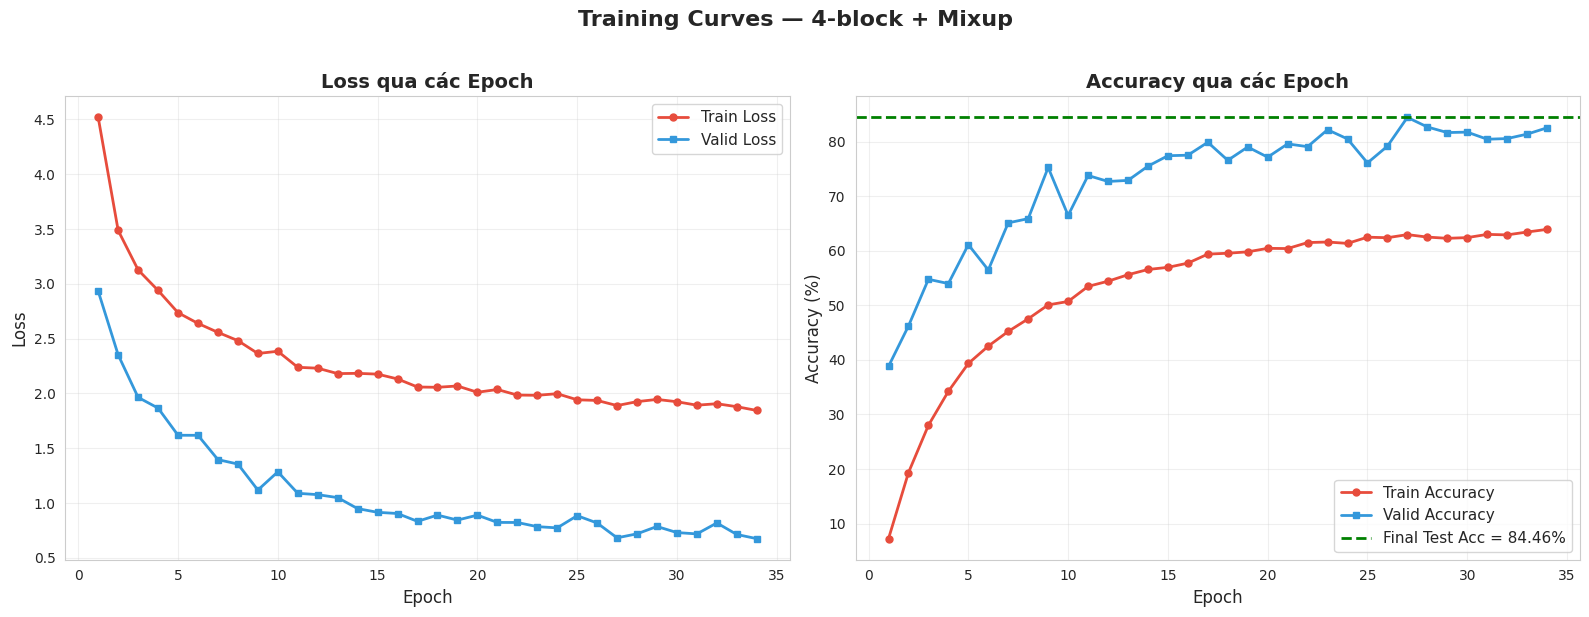

✅ Đã lưu: plot_1_training_curves.png


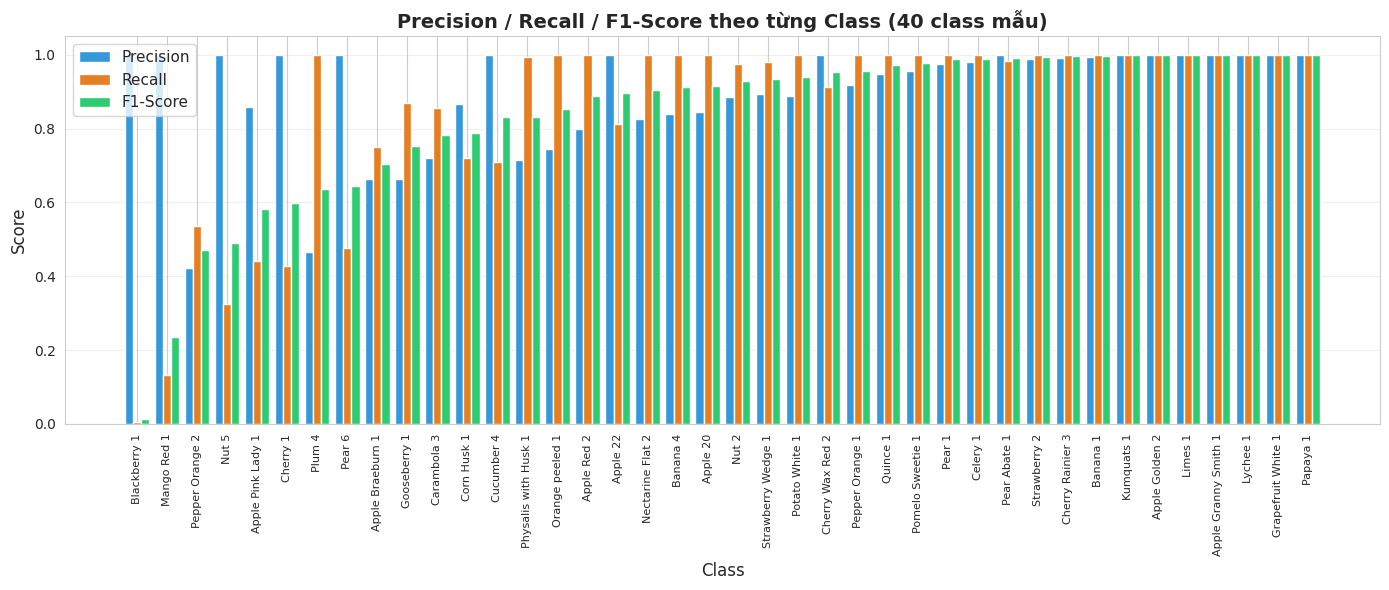

✅ Đã lưu: plot_2_precision_recall_f1.png


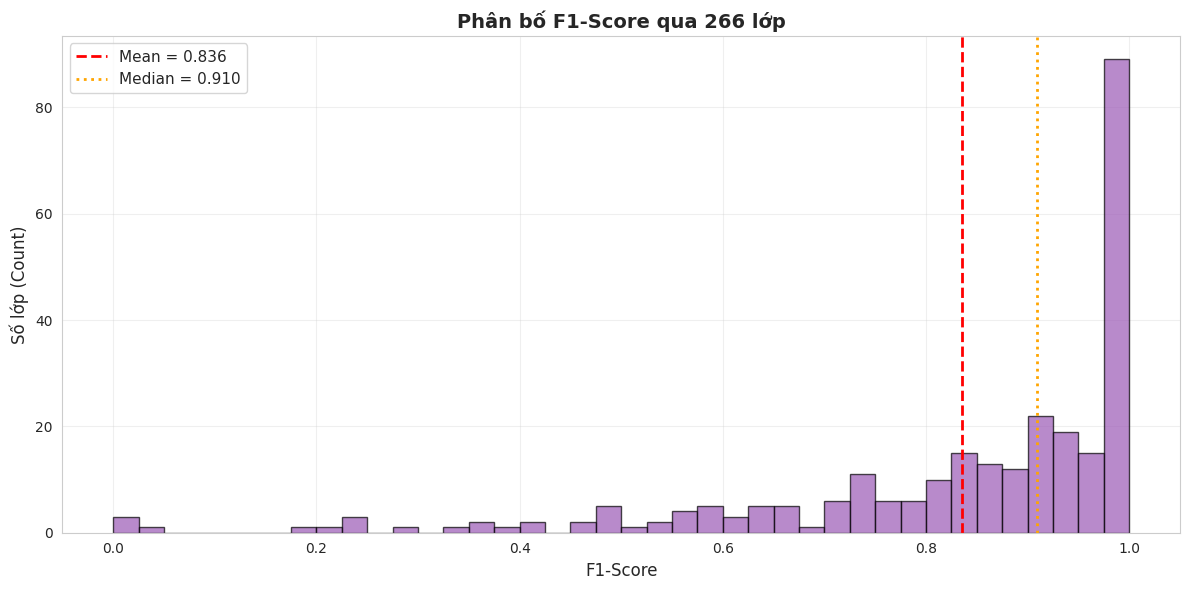

✅ Đã lưu: plot_3_f1_distribution.png


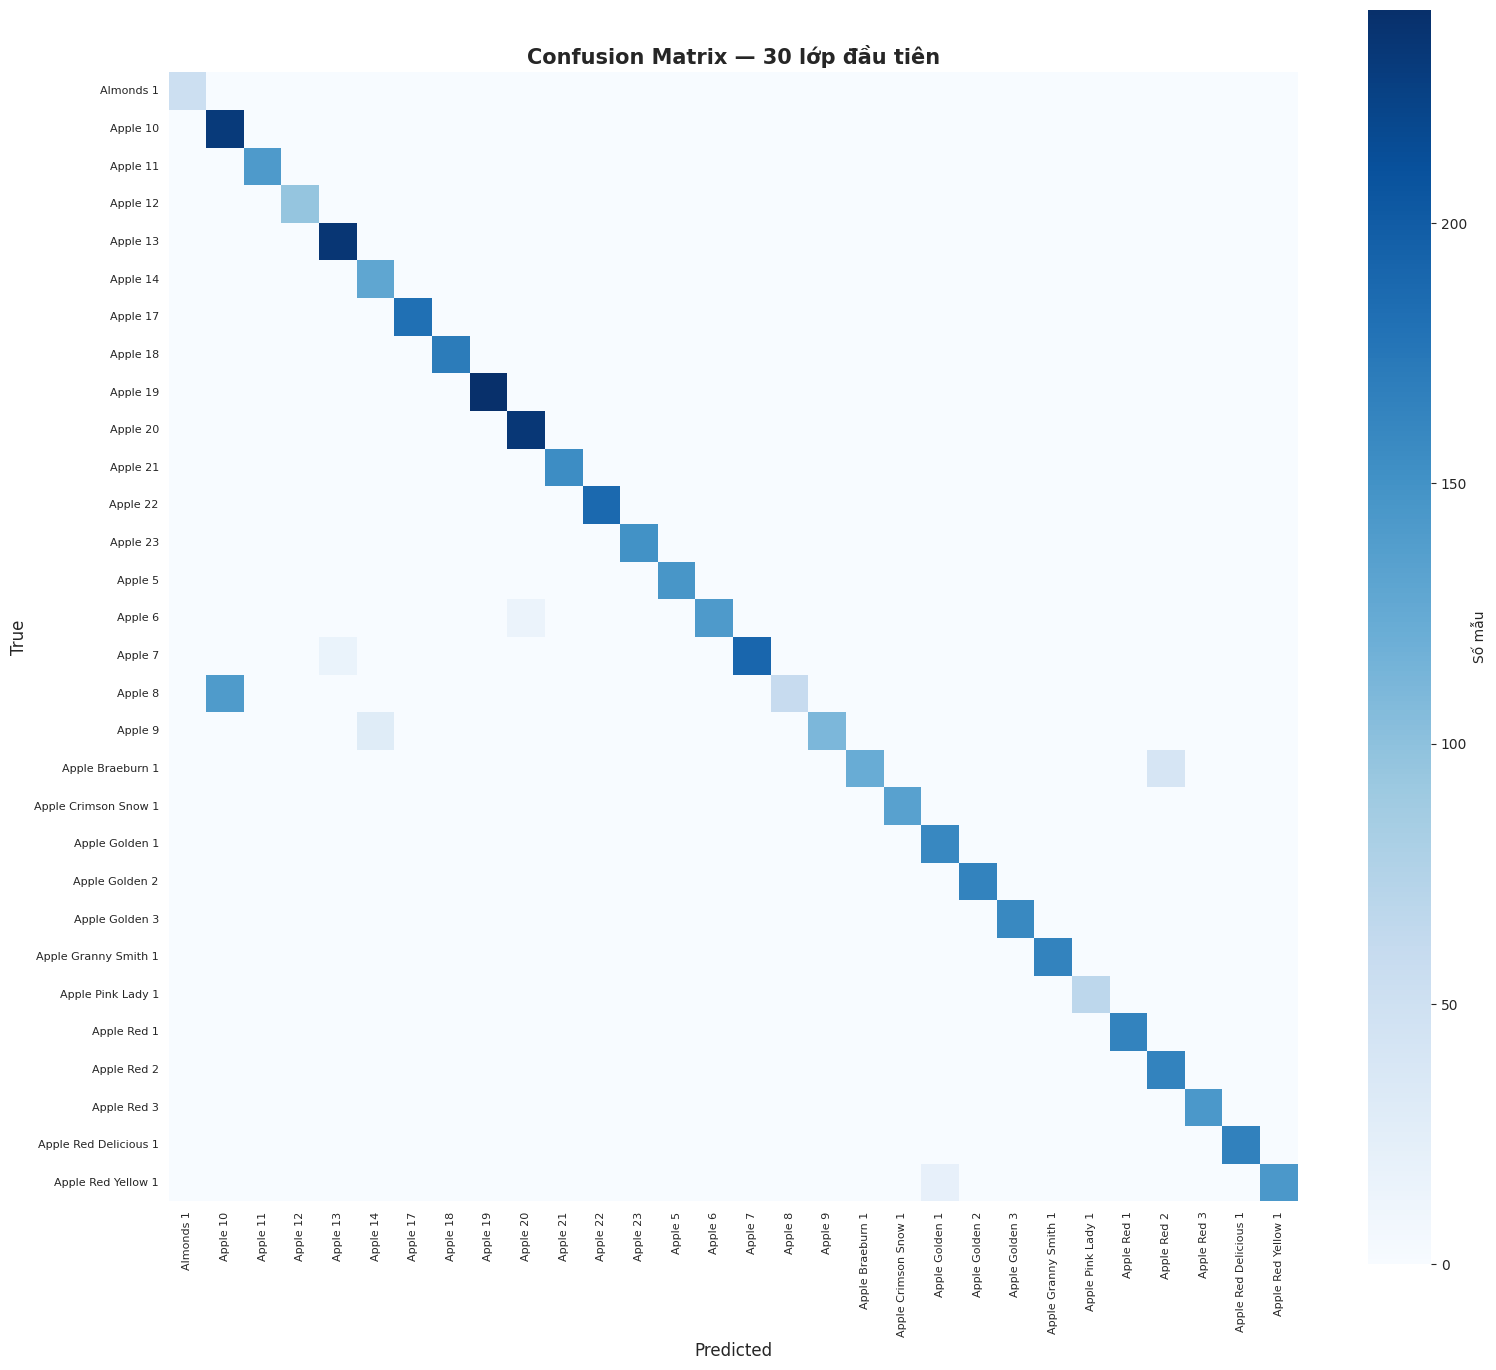

✅ Đã lưu: plot_4_confusion_matrix.png


/tmp/ipykernel_24/2869230457.py:144: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Count", y=pair_labels, data=errors_df,


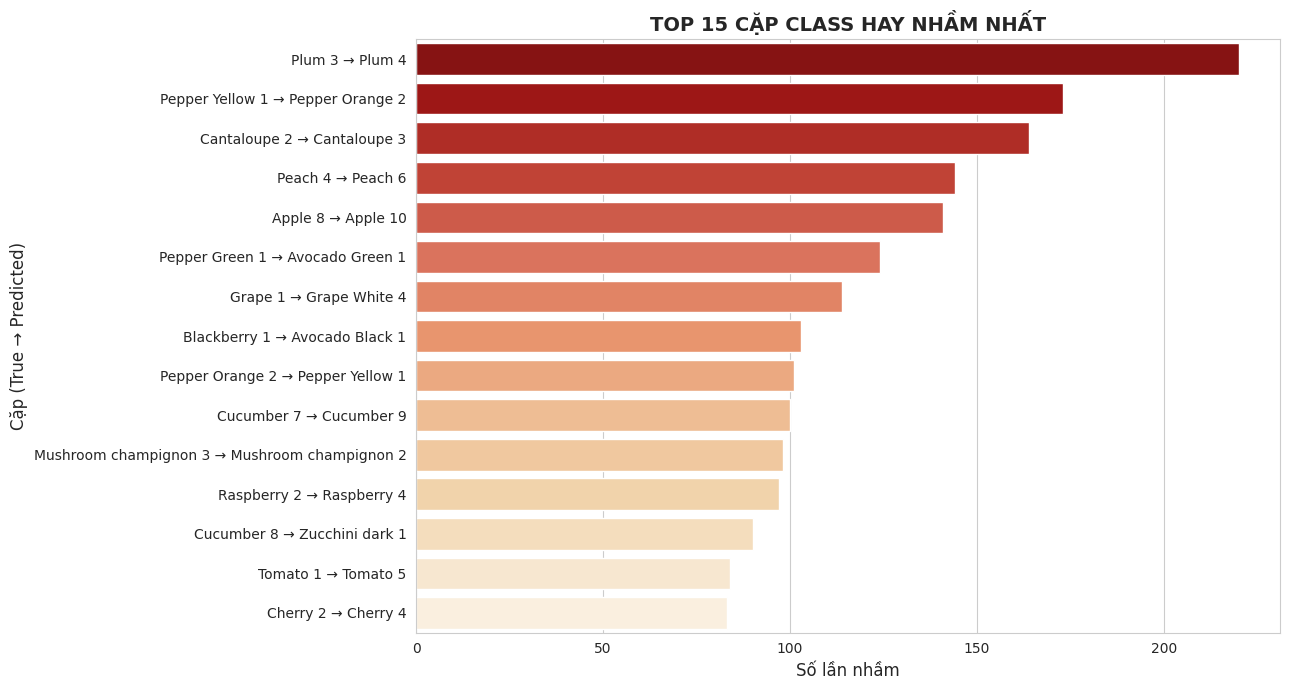

✅ Đã lưu: plot_5_top_errors.png


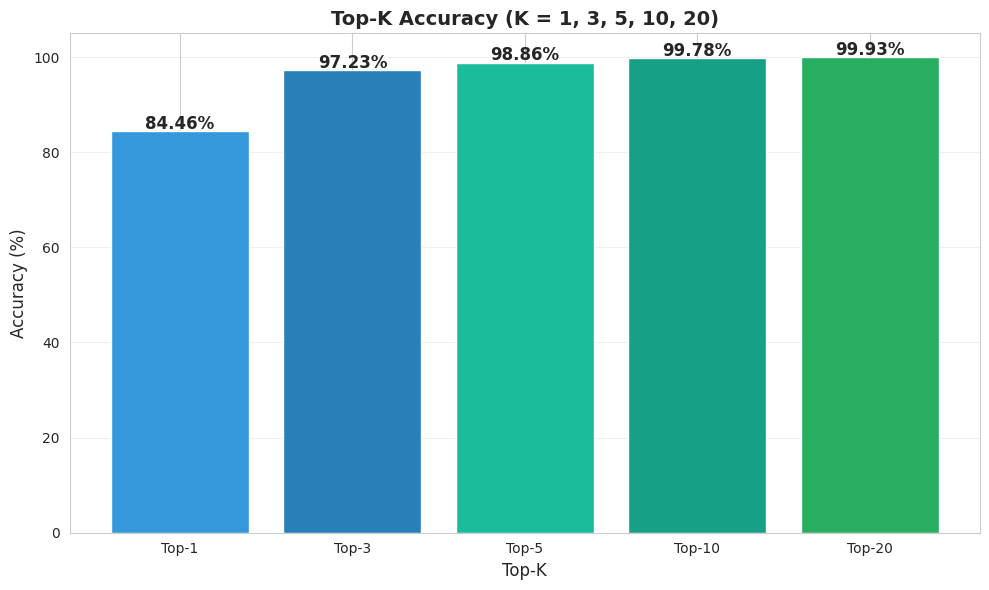

✅ Đã lưu: plot_6_topk_accuracy.png

🎉 HOÀN THÀNH — ĐÃ LƯU 6 ĐỒ THỊ


In [9]:
# =========================================================
# CELL 10B — VẼ TẤT CẢ ĐỒ THỊ ĐÁNH GIÁ
# =========================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'DejaVu Sans'

# ==========================================
# ĐỒ THỊ 1: TRAINING CURVES (Loss + Accuracy qua epoch)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

epochs = range(1, len(history["train_loss"]) + 1)

# Loss
axes[0].plot(epochs, history["train_loss"], 'o-', label="Train Loss", 
             linewidth=2, markersize=5, color='#e74c3c')
axes[0].plot(epochs, history["valid_loss"], 's-', label="Valid Loss", 
             linewidth=2, markersize=5, color='#3498db')
axes[0].set_xlabel("Epoch", fontsize=12)
axes[0].set_ylabel("Loss", fontsize=12)
axes[0].set_title("Loss qua các Epoch", fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

# Accuracy
axes[1].plot(epochs, [a*100 for a in history["train_acc"]], 'o-', 
             label="Train Accuracy", linewidth=2, markersize=5, color='#e74c3c')
axes[1].plot(epochs, [a*100 for a in history["valid_acc"]], 's-', 
             label="Valid Accuracy", linewidth=2, markersize=5, color='#3498db')
axes[1].axhline(y=test_acc*100, color='green', linestyle='--', 
                label=f'Final Test Acc = {test_acc*100:.2f}%', linewidth=2)
axes[1].set_xlabel("Epoch", fontsize=12)
axes[1].set_ylabel("Accuracy (%)", fontsize=12)
axes[1].set_title("Accuracy qua các Epoch", fontsize=14, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.suptitle("Training Curves — 4-block + Mixup", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig("/kaggle/working/plot_1_training_curves.png", dpi=130, bbox_inches='tight')
plt.show()
print("✅ Đã lưu: plot_1_training_curves.png")


# ==========================================
# ĐỒ THỊ 2: PRECISION / RECALL / F1 (per class)
# ==========================================
fig, ax = plt.subplots(figsize=(14, 6))

# Lấy 40 class ngẫu nhiên để hiển thị
sample_idx = np.random.choice(N_CLASSES, 40, replace=False)
sample_df = per_class_df.iloc[sample_idx].sort_values("F1-Score")

x = np.arange(len(sample_df))
width = 0.27

ax.bar(x - width, sample_df["Precision"], width, label="Precision", color='#3498db')
ax.bar(x,          sample_df["Recall"],   width, label="Recall",   color='#e67e22')
ax.bar(x + width,  sample_df["F1-Score"], width, label="F1-Score", color='#2ecc71')

ax.set_xlabel("Class", fontsize=12)
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Precision / Recall / F1-Score theo từng Class (40 class mẫu)",
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(sample_df["Class"], rotation=90, fontsize=8)
ax.legend(fontsize=11)
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("/kaggle/working/plot_2_precision_recall_f1.png", dpi=130, bbox_inches='tight')
plt.show()
print("✅ Đã lưu: plot_2_precision_recall_f1.png")


# ==========================================
# ĐỒ THỊ 3: PHÂN BỐ F1-SCORE (Histogram)
# ==========================================
fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(per_class_df["F1-Score"], bins=40, color='#9b59b6', edgecolor='black', alpha=0.7)
ax.axvline(per_class_df["F1-Score"].mean(), color='red', linestyle='--', linewidth=2,
           label=f'Mean = {per_class_df["F1-Score"].mean():.3f}')
ax.axvline(per_class_df["F1-Score"].median(), color='orange', linestyle=':', linewidth=2,
           label=f'Median = {per_class_df["F1-Score"].median():.3f}')

ax.set_xlabel("F1-Score", fontsize=12)
ax.set_ylabel("Số lớp (Count)", fontsize=12)
ax.set_title("Phân bố F1-Score qua 266 lớp", fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/plot_3_f1_distribution.png", dpi=130, bbox_inches='tight')
plt.show()
print("✅ Đã lưu: plot_3_f1_distribution.png")


# ==========================================
# ĐỒ THỊ 4: CONFUSION MATRIX (30 class đầu)
# ==========================================
cm = confusion_matrix(all_labels, all_preds)

TOP_N = 30
cm_top = cm[:TOP_N, :TOP_N]

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_top, annot=False, cmap="Blues", cbar_kws={"label": "Số mẫu"},
            xticklabels=train_data.classes[:TOP_N],
            yticklabels=train_data.classes[:TOP_N],
            ax=ax, square=True)

ax.set_title(f"Confusion Matrix — {TOP_N} lớp đầu tiên", fontsize=15, fontweight='bold')
ax.set_xlabel("Predicted", fontsize=12)
ax.set_ylabel("True", fontsize=12)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)

plt.tight_layout()
plt.savefig("/kaggle/working/plot_4_confusion_matrix.png", dpi=130, bbox_inches='tight')
plt.show()
print("✅ Đã lưu: plot_4_confusion_matrix.png")


# ==========================================
# ĐỒ THỊ 5: TOP 15 CẶP LỚP HAY NHẦM NHẤT
# ==========================================
errors = []
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if i != j and cm[i, j] > 5:  # Chỉ lấy cặp nhầm > 5 lần
            errors.append((train_data.classes[i], train_data.classes[j], int(cm[i, j])))

errors_df = pd.DataFrame(errors, columns=["True", "Predicted", "Count"])
errors_df = errors_df.sort_values("Count", ascending=False).head(15)

if len(errors_df) > 0:
    fig, ax = plt.subplots(figsize=(13, 7))
    pair_labels = errors_df["True"] + " → " + errors_df["Predicted"]
    
    sns.barplot(x="Count", y=pair_labels, data=errors_df, 
                palette="OrRd_r", ax=ax)
    
    ax.set_xlabel("Số lần nhầm", fontsize=12)
    ax.set_ylabel("Cặp (True → Predicted)", fontsize=12)
    ax.set_title("TOP 15 CẶP CLASS HAY NHẦM NHẤT", fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig("/kaggle/working/plot_5_top_errors.png", dpi=130, bbox_inches='tight')
    plt.show()
    print("✅ Đã lưu: plot_5_top_errors.png")
    errors_df.to_csv("/kaggle/working/top_errors.csv", index=False)


# ==========================================
# ĐỒ THỊ 6: PSNR THAY THẾ (nếu cần — không có ý nghĩa Classification)
# → Vẽ Precision@K thay thế
# ==========================================
from sklearn.metrics import top_k_accuracy_score

ks = [1, 3, 5, 10, 20]
top_k_accs = []
for k in ks:
    acc = top_k_accuracy_score(all_labels, all_probs, k=k, labels=range(N_CLASSES))
    top_k_accs.append(acc * 100)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar([f"Top-{k}" for k in ks], top_k_accs, 
              color=['#3498db', '#2980b9', '#1abc9c', '#16a085', '#27ae60'])

# Ghi số trên đầu cột
for bar, acc in zip(bars, top_k_accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{acc:.2f}%', ha='center', fontsize=12, fontweight='bold')

ax.set_xlabel("Top-K", fontsize=12)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.set_title("Top-K Accuracy (K = 1, 3, 5, 10, 20)", fontsize=14, fontweight='bold')
ax.set_ylim([0, 105])
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig("/kaggle/working/plot_6_topk_accuracy.png", dpi=130, bbox_inches='tight')
plt.show()
print("✅ Đã lưu: plot_6_topk_accuracy.png")

print("\n" + "=" * 60)
print("🎉 HOÀN THÀNH — ĐÃ LƯU 6 ĐỒ THỊ")
print("=" * 60)

In [10]:
# =========================================================
# CELL 10C — CLASSIFICATION REPORT CHI TIẾT
# =========================================================
from sklearn.metrics import classification_report

# Report chi tiết cho tất cả 266 lớp
report_str = classification_report(
    all_labels, all_preds,
    target_names=train_data.classes,
    digits=4, zero_division=0
)

print("=" * 60)
print("CLASSIFICATION REPORT CHI TIẾT (266 lớp)")
print("=" * 60)
print(report_str[:3000])  # In 3000 ký tự đầu (do dài)
print("\n... (còn tiếp, xem file full bên dưới)")

# Lưu ra file TXT
with open("/kaggle/working/classification_report_full.txt", "w", encoding="utf-8") as f:
    f.write("=" * 70 + "\n")
    f.write("CLASSIFICATION REPORT — MODEL 4-BLOCK + MIXUP\n")
    f.write("=" * 70 + "\n\n")
    f.write(f"Test Accuracy      : {test_acc*100:.2f}%\n")
    f.write(f"Top-5 Accuracy     : {top5_acc*100:.2f}%\n")
    f.write(f"Precision (weighted): {test_precision*100:.2f}%\n")
    f.write(f"Recall (weighted)   : {test_recall*100:.2f}%\n")
    f.write(f"F1-Score (weighted) : {test_f1*100:.2f}%\n")
    f.write(f"Num classes         : {N_CLASSES}\n")
    f.write(f"Num test samples    : {len(all_labels):,}\n\n")
    f.write("=" * 70 + "\n")
    f.write("CHI TIẾT TỪNG LỚP\n")
    f.write("=" * 70 + "\n\n")
    f.write(report_str)

print("\n📄 Đã lưu: classification_report_full.txt")

CLASSIFICATION REPORT CHI TIẾT (266 lớp)
                        precision    recall  f1-score   support

             Almonds 1     0.9636    0.6883    0.8030        77
              Apple 10     0.5984    1.0000    0.7488       231
              Apple 11     1.0000    1.0000    1.0000       142
              Apple 12     1.0000    0.6234    0.7680       154
              Apple 13     0.9216    1.0000    0.9592       235
              Apple 14     0.6973    0.8377    0.7611       154
              Apple 17     1.0000    0.9005    0.9476       201
              Apple 18     1.0000    0.7125    0.8321       240
              Apple 19     1.0000    1.0000    1.0000       241
              Apple 20     0.8448    1.0000    0.9159       234
              Apple 21     0.9688    0.9568    0.9627       162
              Apple 22     1.0000    0.8139    0.8974       231
              Apple 23     1.0000    0.9615    0.9804       156
               Apple 5     1.0000    1.0000    1.0000       14

  CELL 11: TỔNG KẾT CUỐI CÙNG

📦 PHẦN 1: LOAD BEST MODEL
-----------------------------------------------------------------
  ✅ Loaded: /kaggle/working/best_fruit360_cnn.pth
  ✅ Số lớp: 273
  ✅ IMG_SIZE: 64
  ✅ Best val_acc: 84.46%

🎨 PHẦN 2: VISUALIZE LỚP CONV ĐẦU + CUỐI
-----------------------------------------------------------------
  Ảnh test: Almonds 1 — r0_103_100.jpg
  Input shape: torch.Size([1, 3, 64, 64])

  Lớp Conv ĐẦU : shape = (32, 64, 64)
                 → 32 kênh (đặc trưng cơ bản: cạnh, màu)

  Lớp Conv CUỐI: shape = (256, 8, 8)
                 → 256 kênh (đặc trưng trừu tượng phức tạp)


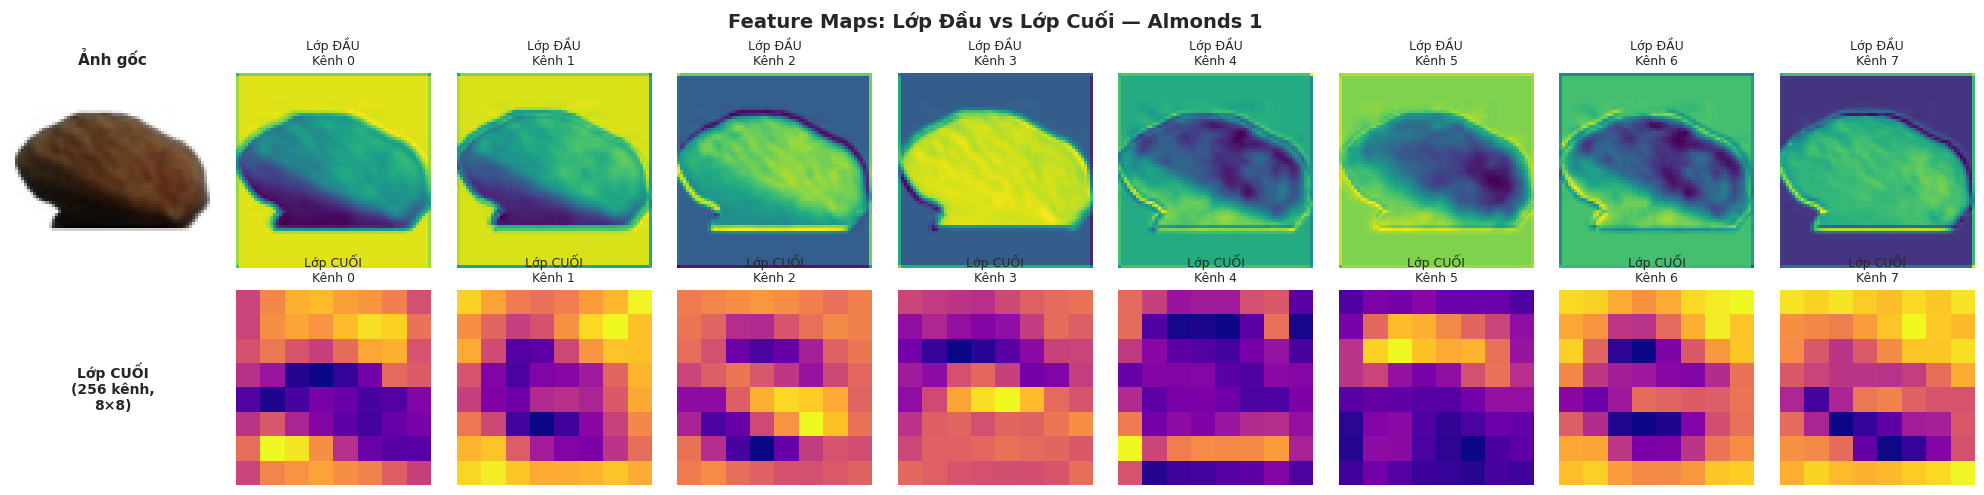


  ✅ Đã lưu: cell11_feature_maps.png


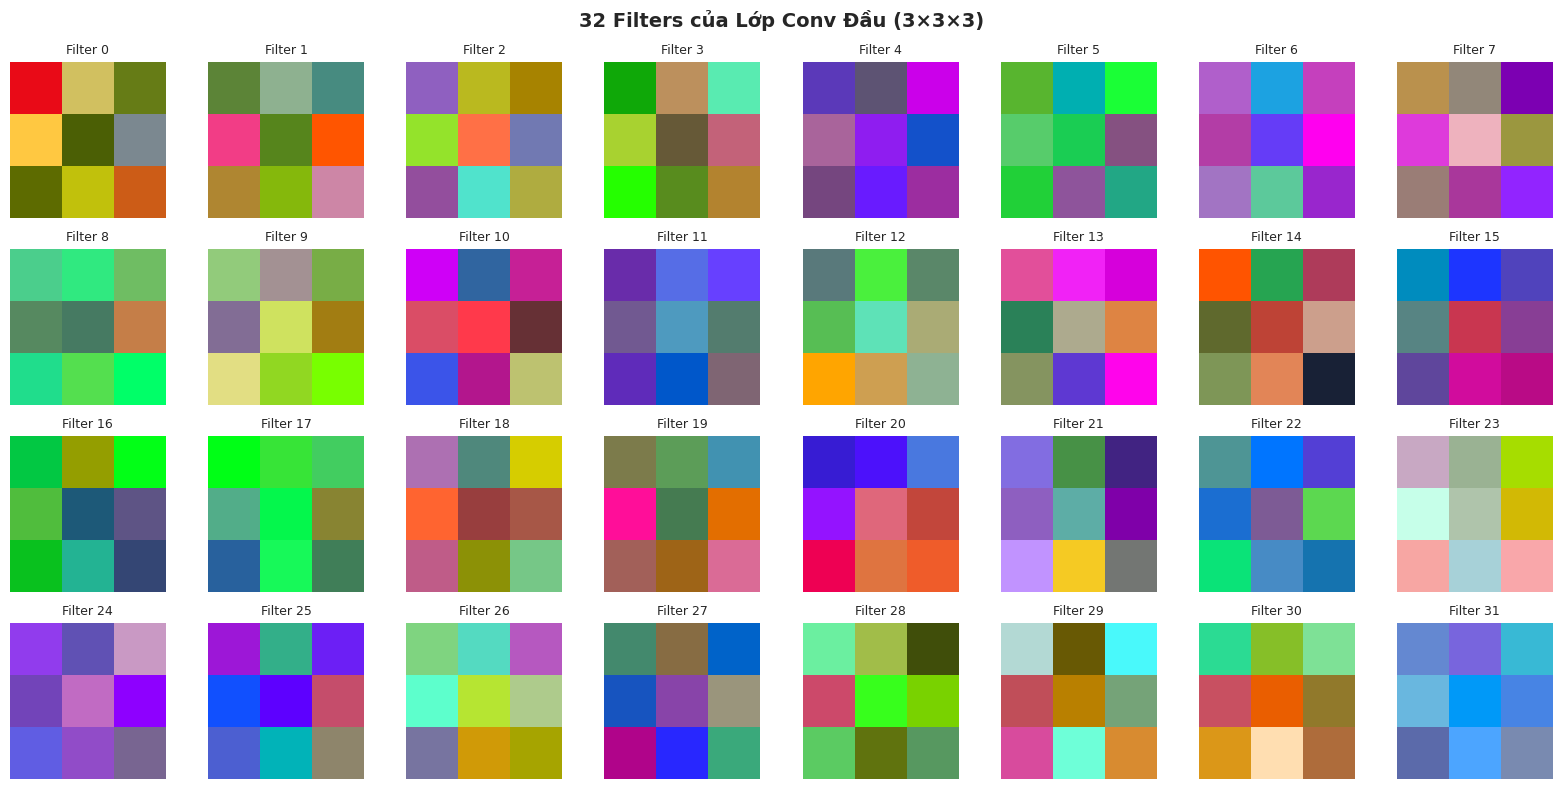

  ✅ Đã lưu: cell11_filters.png

💾 PHẦN 3: LƯU MODEL FINAL
-----------------------------------------------------------------
  ✅ Đã lưu: /kaggle/working/fruit360_4block_final.pth
  ✅ Kích thước: 1.77 MB

📊 PHẦN 4: TÓM TẮT KẾT QUẢ
-----------------------------------------------------------------
  TÓM TẮT KẾT QUẢ — MODEL 4-BLOCK + MIXUP
  Dataset           : Fruits-360 (266 lớp)
  IMG_SIZE          : 64×64
  Kiến trúc          : 4-block CNN + Mixup + CutMix
  Tổng params        : 459,537
  Kích thước model   : 1.77 MB
  
  Best Valid Acc     : 84.46%
  Final Test Acc     : 84.46% (từ Cell 10A)
  Top-5 Accuracy     : 98.86%
  Precision (weighted): 87.78%
  Recall (weighted)   : 84.46%
  F1-Score (weighted) : 83.40%
  

  ✅ Đã lưu: cell11_summary.txt

📥 PHẦN 5: CHECKLIST FILE CẦN TẢI VỀ
-----------------------------------------------------------------

  FILE                                     TRẠNG THÁI            SIZE
  ---------------------------------------- --------------- ----------

In [11]:
# =========================================================
# CELL 11 — TỔNG KẾT: SAVE MODEL + VISUALIZE + CHECKLIST
# =========================================================
import torch
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

OUT_DIR = "/kaggle/working"

print("=" * 65)
print("  CELL 11: TỔNG KẾT CUỐI CÙNG")
print("=" * 65)

# =========================================================
# PHẦN 1: LOAD BEST MODEL
# =========================================================
print("\n📦 PHẦN 1: LOAD BEST MODEL")
print("-" * 65)

ckpt = torch.load(CKPT, map_location=device)
model.load_state_dict(ckpt["model_state"])
model.eval()

print(f"  ✅ Loaded: {CKPT}")
print(f"  ✅ Số lớp: {len(ckpt['classes'])}")
print(f"  ✅ IMG_SIZE: {ckpt['img_size']}")
print(f"  ✅ Best val_acc: {ckpt['val_acc']*100:.2f}%")

# =========================================================
# PHẦN 2: VISUALIZE LỚP CONV ĐẦU + CUỐI (theo yêu cầu cô giáo)
# =========================================================
print("\n🎨 PHẦN 2: VISUALIZE LỚP CONV ĐẦU + CUỐI")
print("-" * 65)

# ---- Lấy 1 ảnh test ----
sample_cls = "Banana"  # ⭐ Đổi thành lớp khác nếu muốn
files = glob.glob(os.path.join(TEST_DIR, sample_cls, "*"))
if not files:
    sample_cls = train_data.classes[0]
    files = glob.glob(os.path.join(TEST_DIR, sample_cls, "*"))

img_path = files[0]
img_pil = Image.open(img_path).convert("RGB")
img_show = np.array(img_pil.resize((IMG_SIZE, IMG_SIZE))) / 255.0

# Transform
img_tensor = base_trans(transforms.functional.to_image(img_pil))
img_tensor = img_tensor.unsqueeze(0).to(device)

print(f"  Ảnh test: {sample_cls} — {os.path.basename(img_path)}")
print(f"  Input shape: {img_tensor.shape}")

# ---- Hook để lấy activation của lớp đầu + cuối ----
activations = {}

def hook_first(module, input, output):
    activations["first"] = output.detach()

def hook_last(module, input, output):
    activations["last"] = output.detach()

# Lớp Conv đầu (features[0])
first_conv = model.features[0].model[0]
# Lớp Conv cuối (features[3] trong 4-block)
last_conv = model.features[3].model[0]

h1 = first_conv.register_forward_hook(hook_first)
h2 = last_conv.register_forward_hook(hook_last)

with torch.no_grad():
    _ = model(img_tensor)

h1.remove()
h2.remove()

feat_first = activations["first"][0].cpu().numpy()   # (32, H, W)
feat_last  = activations["last"][0].cpu().numpy()    # (256, H/16, W/16)

print(f"\n  Lớp Conv ĐẦU : shape = {feat_first.shape}")
print(f"                 → 32 kênh (đặc trưng cơ bản: cạnh, màu)")
print(f"\n  Lớp Conv CUỐI: shape = {feat_last.shape}")
print(f"                 → 256 kênh (đặc trưng trừu tượng phức tạp)")

# ---- Hàm chuẩn hóa ----
def norm01(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

# ---- Vẽ feature maps ----
fig, axes = plt.subplots(2, 9, figsize=(20, 5))

# Hàng trên: ảnh gốc + 8 kênh lớp ĐẦU
axes[0, 0].imshow(img_show)
axes[0, 0].set_title("Ảnh gốc", fontsize=11, fontweight="bold")
axes[0, 0].axis("off")

for i in range(8):
    axes[0, i + 1].imshow(norm01(feat_first[i]), cmap="viridis")
    axes[0, i + 1].set_title(f"Lớp ĐẦU\nKênh {i}", fontsize=9)
    axes[0, i + 1].axis("off")

# Hàng dưới: 8 kênh lớp CUỐI
for i in range(8):
    axes[1, i + 1].imshow(norm01(feat_last[i]), cmap="plasma")
    axes[1, i + 1].set_title(f"Lớp CUỐI\nKênh {i}", fontsize=9)
    axes[1, i + 1].axis("off")

axes[1, 0].text(0.5, 0.5,
                f"Lớp CUỐI\n({feat_last.shape[0]} kênh,\n{feat_last.shape[1]}×{feat_last.shape[2]})",
                ha="center", va="center", fontsize=10, fontweight="bold")
axes[1, 0].axis("off")

plt.suptitle(f"Feature Maps: Lớp Đầu vs Lớp Cuối — {sample_cls}",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "cell11_feature_maps.png"), dpi=120, bbox_inches="tight")
plt.show()
print(f"\n  ✅ Đã lưu: cell11_feature_maps.png")

# ---- Vẽ 32 filters của lớp Conv đầu ----
fig, axes = plt.subplots(4, 8, figsize=(16, 8))
weights = first_conv.weight.data.cpu().numpy()   # (32, 3, 3, 3)

for i in range(32):
    filt = weights[i].transpose(1, 2, 0)
    axes.flatten()[i].imshow(norm01(filt))
    axes.flatten()[i].set_title(f"Filter {i}", fontsize=9)
    axes.flatten()[i].axis("off")

plt.suptitle("32 Filters của Lớp Conv Đầu (3×3×3)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "cell11_filters.png"), dpi=120, bbox_inches="tight")
plt.show()
print(f"  ✅ Đã lưu: cell11_filters.png")

# =========================================================
# PHẦN 3: LƯU MODEL FINAL (để tải về máy)
# =========================================================
print("\n💾 PHẦN 3: LƯU MODEL FINAL")
print("-" * 65)

FINAL_CKPT = os.path.join(OUT_DIR, "fruit360_4block_final.pth")
torch.save({
    "model_state": model.state_dict(),
    "classes": train_data.classes,
    "img_size": IMG_SIZE,
    "val_acc": ckpt["val_acc"],
    "architecture": "4-block CNN + Mixup",
    "total_params": sum(p.numel() for p in model.parameters()),
}, FINAL_CKPT)

size_mb = os.path.getsize(FINAL_CKPT) / (1024 ** 2)
print(f"  ✅ Đã lưu: {FINAL_CKPT}")
print(f"  ✅ Kích thước: {size_mb:.2f} MB")

# =========================================================
# PHẦN 4: TÓM TẮT KẾT QUẢ
# =========================================================
print("\n📊 PHẦN 4: TÓM TẮT KẾT QUẢ")
print("-" * 65)

summary_lines = [
    "=" * 60,
    "TÓM TẮT KẾT QUẢ — MODEL 4-BLOCK + MIXUP",
    "=" * 60,
    f"Dataset           : Fruits-360 (266 lớp)",
    f"IMG_SIZE          : {IMG_SIZE}×{IMG_SIZE}",
    f"Kiến trúc          : 4-block CNN + Mixup + CutMix",
    f"Tổng params        : {sum(p.numel() for p in model.parameters()):,}",
    f"Kích thước model   : {size_mb:.2f} MB",
    "",
    f"Best Valid Acc     : {ckpt['val_acc']*100:.2f}%",
    f"Final Test Acc     : {test_acc*100:.2f}% (từ Cell 10A)",
    f"Top-5 Accuracy     : {top5_acc*100:.2f}%",
    f"Precision (weighted): {test_precision*100:.2f}%",
    f"Recall (weighted)   : {test_recall*100:.2f}%",
    f"F1-Score (weighted) : {test_f1*100:.2f}%",
    "",
    "=" * 60,
]

for line in summary_lines:
    print(f"  {line}")

# Lưu summary
with open(os.path.join(OUT_DIR, "cell11_summary.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(summary_lines))

print(f"\n  ✅ Đã lưu: cell11_summary.txt")

# =========================================================
# PHẦN 5: CHECKLIST FILE CẦN TẢI VỀ
# =========================================================
print("\n📥 PHẦN 5: CHECKLIST FILE CẦN TẢI VỀ")
print("-" * 65)

# Danh sách file cần có
required_files = {
    "fruit360_4block_final.pth": "Model chính thức (dùng để nộp)",
    "test_summary.csv": "Bảng tóm tắt metrics",
    "per_class_metrics.csv": "Precision/Recall/F1 từng lớp",
    "classification_report_full.txt": "Báo cáo chi tiết 266 lớp",
    "top_errors.csv": "Top 15 cặp lớp nhầm",
    "plot_1_training_curves.png": "Đồ thị Loss + Accuracy",
    "plot_2_precision_recall_f1.png": "Đồ thị 3 metric per-class",
    "plot_3_f1_distribution.png": "Phân bố F1-Score",
    "plot_4_confusion_matrix.png": "Confusion Matrix",
    "plot_5_top_errors.png": "Top lỗi nhầm",
    "plot_6_topk_accuracy.png": "Top-K Accuracy",
    "cell11_feature_maps.png": "Feature maps lớp đầu/cuối",
    "cell11_filters.png": "32 filters lớp đầu",
    "cell11_summary.txt": "Tóm tắt kết quả",
}

print(f"\n  {'FILE':<40} {'TRẠNG THÁI':<15} {'SIZE':>10}")
print(f"  {'-'*40} {'-'*15} {'-'*10}")

missing = []
for filename, desc in required_files.items():
    path = os.path.join(OUT_DIR, filename)
    if os.path.exists(path):
        size_kb = os.path.getsize(path) / 1024
        status = "✅ Có"
        print(f"  {filename:<40} {status:<15} {size_kb:>8.1f} KB")
    else:
        status = "❌ Thiếu"
        missing.append(filename)
        print(f"  {filename:<40} {status:<15} {'---':>10}")

# =========================================================
# PHẦN 6: HƯỚNG DẪN TẢI VỀ
# =========================================================
print("\n" + "=" * 65)
print("  📥 HƯỚNG DẪN TẢI FILE VỀ MÁY")
print("=" * 65)

if len(missing) == 0:
    print("  ✅ TẤT CẢ FILE ĐÃ ĐẦY ĐỦ!")
    print("\n  Cách tải:")
    print("  1. Nhìn khung bên phải → Tab 'Data'")
    print("  2. Mở thư mục '/kaggle/working'")
    print("  3. Chọn tất cả file → Nhấn biểu tượng ⬇️ (Download)")
    print("\n  Hoặc: Save Version → Save & Run All → Vào Output → Download All")
else:
    print(f"  ⚠️  Thiếu {len(missing)} file: {missing}")
    print("  → Chạy lại Cell 10A, 10B, 10C trước")

print("\n" + "=" * 65)
print("  🎉 HOÀN THÀNH TOÀN BỘ DỰ ÁN!")
print("=" * 65)

In [12]:
# =========================================================
# CELL 12 — NÉN TẤT CẢ KẾT QUẢ THÀNH 1 FILE ZIP
# =========================================================
import os
import glob
import zipfile

OUT_DIR = "/kaggle/working"
ZIP_NAME = "Fruit360_Final_Results.zip"
ZIP_PATH = os.path.join(OUT_DIR, ZIP_NAME)

print("=" * 65)
print("  CELL 12: ĐANG NÉN TẤT CẢ KẾT QUẢ")
print("=" * 65)

# 1. Tìm tất cả các file kết quả cần nén
extensions = ["*.png", "*.csv", "*.txt", "*.pth"]
files_to_zip = []

for ext in extensions:
    files_to_zip.extend(glob.glob(os.path.join(OUT_DIR, ext)))

# Loại bỏ chính file zip (nếu chạy lại lần 2)
if ZIP_PATH in files_to_zip:
    files_to_zip.remove(ZIP_PATH)

print(f"📦 Tìm thấy {len(files_to_zip)} file cần nén:")
for f in sorted(files_to_zip):
    size = os.path.getsize(f) / 1024  # KB
    print(f"   - {os.path.basename(f):40s} ({size:.1f} KB)")

# 2. Tiến hành nén
print(f"\n⏳ Đang nén vào {ZIP_NAME}...")
with zipfile.ZipFile(ZIP_PATH, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_zip:
        # Lưu file với tên ngắn gọn (không lưu đường dẫn dài dòng)
        zipf.write(file, os.path.basename(file))

# 3. Kiểm tra kết quả
if os.path.exists(ZIP_PATH):
    zip_size = os.path.getsize(ZIP_PATH) / (1024 ** 2)  # MB
    print(f"\n✅ NÉN THÀNH CÔNG!")
    print(f"   File: {ZIP_NAME}")
    print(f"   Kích thước: {zip_size:.2f} MB")
    print(f"   Đường dẫn: {ZIP_PATH}")
else:
    print("\n❌ Lỗi: Không tạo được file zip!")

print("\n" + "=" * 65)
print("  📥 HƯỚNG DẪN TẢI FILE ZIP VỀ MÁY")
print("=" * 65)
print("1. Nhìn sang khung bên phải màn hình Kaggle.")
print("2. Chuyển sang tab 'Data'.")
print("3. Mở thư mục '/kaggle/working'.")
print("4. Tìm file 'Fruit360_Final_Results.zip'.")
print("5. Nhấn biểu tượng ⬇️ (Download) bên cạnh file.")
print("=" * 65)

  CELL 12: ĐANG NÉN TẤT CẢ KẾT QUẢ
📦 Tìm thấy 15 file cần nén:
   - best_fruit360_cnn.pth                    (1816.0 KB)
   - cell11_feature_maps.png                  (114.4 KB)
   - cell11_filters.png                       (34.0 KB)
   - cell11_summary.txt                       (0.6 KB)
   - classification_report_full.txt           (17.9 KB)
   - fruit360_4block_final.pth                (1816.3 KB)
   - per_class_metrics.csv                    (13.5 KB)
   - plot_1_training_curves.png               (122.5 KB)
   - plot_2_precision_recall_f1.png           (93.7 KB)
   - plot_3_f1_distribution.png               (41.8 KB)
   - plot_4_confusion_matrix.png              (114.7 KB)
   - plot_5_top_errors.png                    (93.0 KB)
   - plot_6_topk_accuracy.png                 (38.5 KB)
   - test_summary.csv                         (0.2 KB)
   - top_errors.csv                           (0.4 KB)

⏳ Đang nén vào Fruit360_Final_Results.zip...

✅ NÉN THÀNH CÔNG!
   File: Fruit360_Final_Resu